# 01 — Analyse Exploratoire des Données (EDA)

**Projet** : fraud-risk-intelligence-prototype  
**Phase** : J2 — Données  
**Date** : 2026-11-10  
**Référence** : `Matrice_Conformite.md` R056–R075 ; `03_Architecture_Globale_ML.md` §4

**Objectif** : explorer le dataset PaySim brut, produire les 6 figures EDA  
et documenter les 3 décisions qui en découlent pour le J3.

> Ce notebook ne modifie aucune donnée. Il appelle `eda.py` (n° 13)  
> qui sauvegarde les figures dans `artifacts/figures/`.

In [6]:
import os
os.chdir("/Users/ermanw/TENSORATECH/04_APPRENTISSAGE/04_EXERCICES_APPLIQUES/Capstone_Project_1/fraud-risk-intelligence-prototype/02_build/fraud-risk-intelligence-prototype")
# Cellule 1 — Imports
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from src.data.load_paysim import load_raw
from src.data.eda import run_eda
print('Imports OK')

Imports OK


In [7]:
# Cellule 2 — Chargement
df = load_raw()
print(f'Shape : {df.shape}')
print(df.dtypes)
df.head(3)

Shape : (6362620, 11)
step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0


In [8]:
# Cellule 3 — Statistiques descriptives
print(df.describe())
print('\n--- value_counts isFraud ---')
print(df['isFraud'].value_counts())
print('\n--- nulls ---')
print(df.isnull().sum())

               step        amount  oldbalanceOrg  newbalanceOrig  \
count  6.362620e+06  6.362620e+06   6.362620e+06    6.362620e+06   
mean   2.433972e+02  1.798619e+05   8.338831e+05    8.551137e+05   
std    1.423320e+02  6.038582e+05   2.888243e+06    2.924049e+06   
min    1.000000e+00  0.000000e+00   0.000000e+00    0.000000e+00   
25%    1.560000e+02  1.338957e+04   0.000000e+00    0.000000e+00   
50%    2.390000e+02  7.487194e+04   1.420800e+04    0.000000e+00   
75%    3.350000e+02  2.087215e+05   1.073152e+05    1.442584e+05   
max    7.430000e+02  9.244552e+07   5.958504e+07    4.958504e+07   

       oldbalanceDest  newbalanceDest       isFraud  isFlaggedFraud  
count    6.362620e+06    6.362620e+06  6.362620e+06    6.362620e+06  
mean     1.100702e+06    1.224996e+06  1.290820e-03    2.514687e-06  
std      3.399180e+06    3.674129e+06  3.590480e-02    1.585775e-03  
min      0.000000e+00    0.000000e+00  0.000000e+00    0.000000e+00  
25%      0.000000e+00    0.000000e+00

EDA terminée — 6 figures sauvegardées dans artifacts/figures/
  ✅ fig01_class_balance.png
  ✅ fig02_transaction_types.png
  ✅ fig03_amount_distribution.png
  ✅ fig04_fraud_by_type.png
  ✅ fig05_balance_errors.png
  ✅ fig06_correlation_heatmap.png


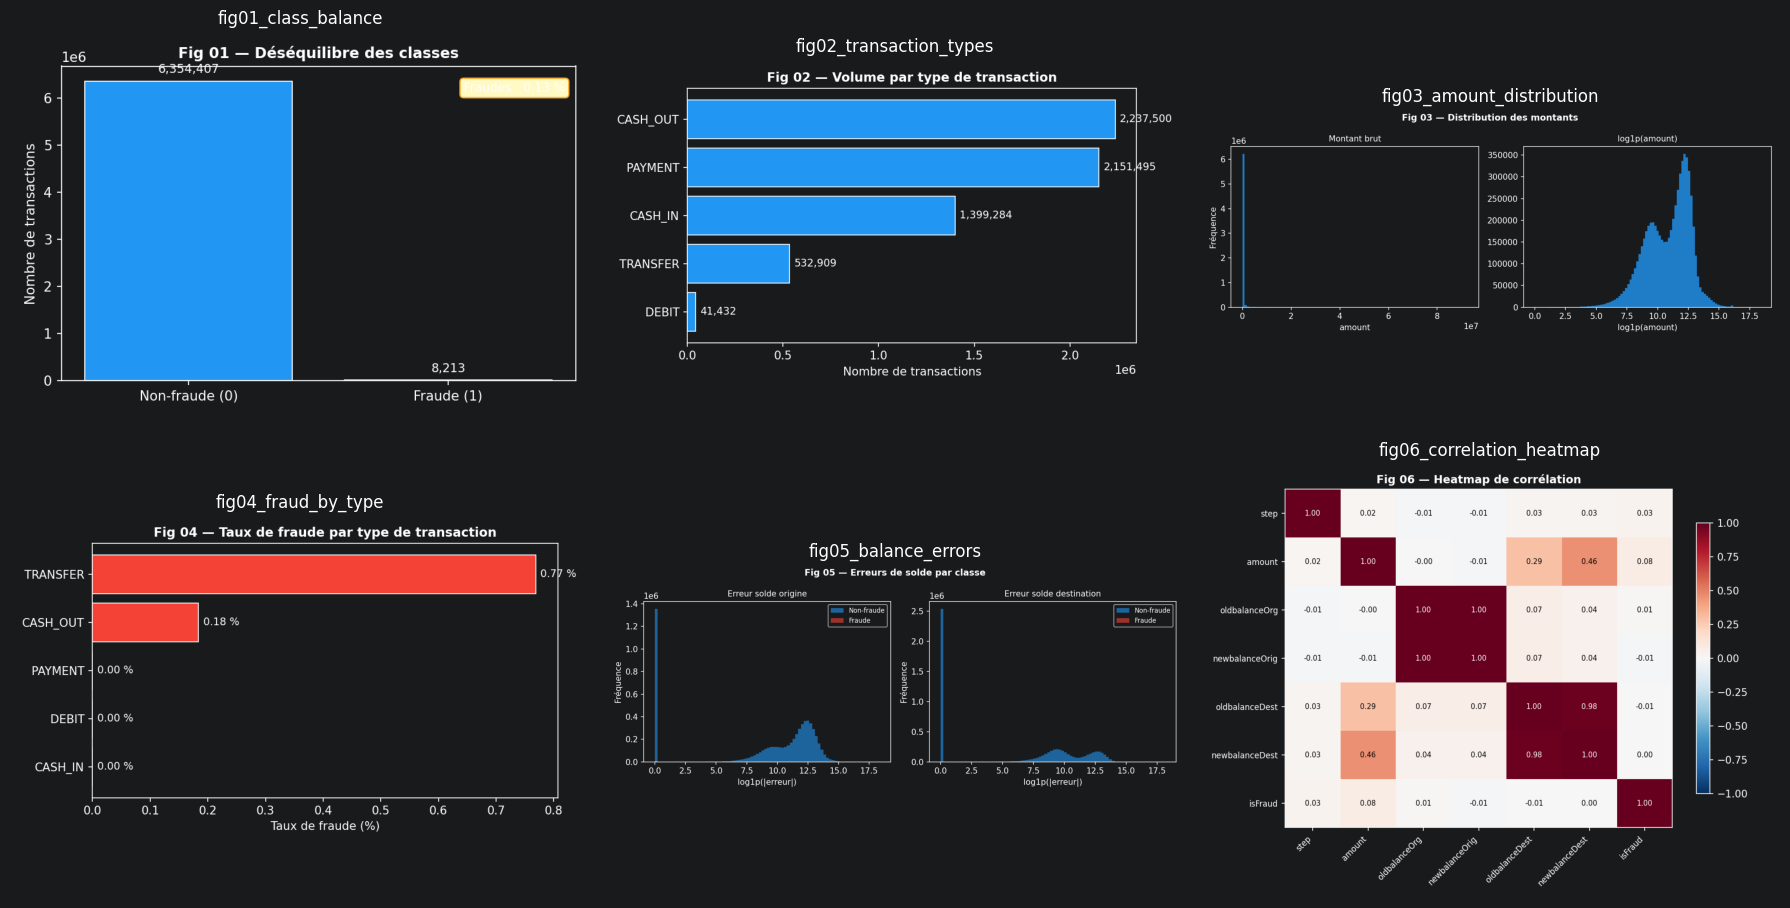

6 figures générées dans artifacts/figures


In [9]:
# Cellule 4 — Figures EDA
output_dir = Path('artifacts/figures')
figures = run_eda(df, output_dir)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, fig_path in zip(axes.flatten(), figures):
    img = mpimg.imread(fig_path)
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(fig_path.stem)
plt.tight_layout()
plt.show()
print(f'{len(figures)} figures générées dans {output_dir}')

## Conclusions J2 → Décisions J3

1. **Déséquilibre de classes** : ~0,13 % de fraudes → métrique PR-AUC et F1, pas accuracy.
2. **Colinéarité** : corrélation 1,00 entre `oldbalanceOrg`/`newbalanceOrig` → analyser VIF au J3.
3. **Types frauduleux** : TRANSFER et CASH_OUT seulement → feature `is_risky_type` envisagée.